![Banner](../images/09_13_banner_rs_soil_moisture.png)

# The Mission and Product Landscape

More than a dozen satellite soil moisture products are freely available, from 36 km daily
radiometer retrievals to 200 m SAR maps, and from four decades of merged climate records to
assimilated model analyses. They differ in band, sensing technique, grid, revisit, latency and the
meaning of their numbers. This notebook builds a comparison table of the products used in the
chapter from NASA's Common Metadata Repository (CMR) and the GeoLattice product registry, places the
missions on a timeline, and compares four of them on the same day over Iowa and its neighbours.

## Overview

### Passive, active and merged

| Family | Products | Strength | Limitation |
|---|---|---|---|
| L-band radiometers | SMAP (2015 to present), SMOS (2009 to present) | best physical sensitivity, 2 to 3 day revisit | 36 to 40 km footprints (9 km gridded) |
| C/X-band radiometers | AMSR-E (2002 to 2011), AMSR2 (2012 to present) | long record, VOD by-product | shallow sensing, saturates over dense vegetation |
| Scatterometers | ASCAT on MetOp (2007 to present) | daily, all weather, 12.5 km | change detection gives degree of saturation |
| SAR | Sentinel-1 (2014 to present), NISAR (2025 to present) | 10 to 200 m, field scale | 6 to 12 day revisit, sensitive to roughness and crops |
| Merged climate records | ESA CCI SM ACTIVE, PASSIVE, COMBINED (1978 to present) | 45 years, consistent | 0.25 degree, sensor changes over time |
| Models and assimilation | SMAP L4 (2015 to present), ERA5-Land (1950 to present), GLDAS, NLDAS | gap free, root zone | model physics and forcing errors |

### Product levels

| Level | Content | Example |
|---|---|---|
| L1 | calibrated brightness temperatures or backscatter in swath | SMAP L1C_TB, Sentinel-1 GRD |
| L2 | geophysical retrieval in swath (half orbit) | SMAP L2_SM_P_E, NSIDC-0799 |
| L3 | daily composite on a fixed grid | SMAP L3_SM_P_E, ESA CCI, NSIDC-0800 |
| L4 | model or assimilation output | SMAP L4_SM (surface and root zone, 3-hourly) |

### Grids and quality

SMAP and SMOS-SMAP products use the Equal-Area Scalable Earth grid version 2.0 (EASE-Grid 2.0,
EPSG:6933) at 36, 9, 3 or 1 km; ESA CCI and ERA5-Land use regular latitude and longitude grids.
Every product carries quality flags (retrieval quality, frozen soil, open water, RFI, dense
vegetation) that must be applied before analysis; notebook 04 shows how.

## Products with GeoLattice

| Function | Purpose |
|---|---|
| `sm.PRODUCTS`, `sm.VERSIONS` | registry of products, identifiers, grids and units used in the chapter |
| `sm.product_info(name)` | one registry entry |
| `sm.product_table(from_cmr=True)` | comparison table with collection metadata from CMR |
| `sm.ease2_grid`, `sm.harmonize` | grids and regridding to one grid |

### Learning objectives

1. Distinguish passive, active, merged and model soil moisture products and their trade-offs.
2. Read collection metadata (versions, periods, data centres) programmatically from CMR.
3. Explain product levels, grids and latency.
4. Compare products of different resolution on the same day and recognize what each one sees.

### Data

| Dataset | Content |
|---|---|
| NASA CMR collection metadata | titles, versions, data centres and periods of the NASA products |
| SMAP L3 (36 km) and L3 Enhanced (9 km), 2024 | daily soil moisture, Iowa region |
| ESA CCI COMBINED v09.2, 2024 | merged soil moisture at 0.25 degree |
| ERA5-Land layer 1 (0 to 7 cm), 2024 | reanalysis soil moisture at 0.5 degree |

### Contents

- Setup
- The product registry
- Collection metadata from CMR
- A timeline of the records
- Latency: how fresh is each product
- Four products on one day
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

import requests  # CMR queries

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


## The product registry

`sm.PRODUCTS` lists, for every product the chapter reads, its provider short name, access route,
grid, nominal resolution, soil moisture and quality variables, units and family.

In [2]:
reg = sm.product_table()  # registry as a table
display(reg[["short_name", "version", "kind", "grid", "res_m", "access", "units"]])  # main columns

,short_name,version,kind,grid,res_m,access,units
name,,,,,,,
SMAP_L3,SPL3SMP,009,passive,EASE2_M36km,36000,earthdata,m3 m-3
SMAP_L3_E,SPL3SMP_E,006,passive,EASE2_M09km,9000,earthdata,m3 m-3
SMAP_L4,SPL4SMGP,008,model,EASE2_M09km,9000,earthdata,m3 m-3
SPL2SMAP_S,SPL2SMAP_S,003,active_passive,EASE2_M03km,3000,earthdata,m3 m-3
SMOS_L3,SMOS_L3_CATDS,NaN,passive,EASE2_M25km,25000,catds,m3 m-3
SMOS_SMAP_L3,NSIDC-0800,2,passive,EASE2_M09km,9000,earthdata,m3 m-3
AMSR2_LPRM,LPRM_AMSR2_DS_A_SOILM3,001,passive,regular_0.1deg,10000,earthdata,m3 m-3
ASCAT_SSM,H SAF SSM,NaN,active,WARP5_12.5km,12500,hsaf,%
ESA_CCI,ESACCI-SOILMOISTURE-L3S,NaN,merged,regular_0.25deg,25000,cci,m3 m-3


## Collection metadata from CMR

CMR is NASA's public catalogue of every Earth science collection and granule. `product_table(from_cmr=True)`
adds the title, data centre and temporal extent of each NASA collection. No login is needed.

In [3]:
cmr = sm.product_table(from_cmr=True)  # registry plus CMR metadata
nasa = cmr.dropna(subset=["title"])  # NASA collections only
display(nasa[["short_name", "version", "data_center", "time_start", "time_end", "title"]])  # metadata

,short_name,version,data_center,time_start,time_end,title
name,,,,,,
SMAP_L3,SPL3SMP,009,NSIDC_CPRD,2015-03-31,present,SMAP L3 Radiometer Global Daily 36 km EASE-Gri...
SMAP_L3_E,SPL3SMP_E,006,NSIDC_CPRD,2015-03-31,present,SMAP Enhanced L3 Radiometer Global and Polar G...
SMAP_L4,SPL4SMGP,008,NSIDC_CPRD,2015-03-31,present,SMAP L4 Global 3-hourly 9 km EASE-Grid Surface...
SPL2SMAP_S,SPL2SMAP_S,003,NSIDC_CPRD,2015-03-31,present,SMAP/Sentinel-1 L2 Radiometer/Radar 30-Second ...
SMOS_SMAP_L3,NSIDC-0800,2,NSIDC_CPRD,2015-03-31,present,SMAP/SMOS L3 Radiometer 9 km EASE-Grid Soil Mo...
AMSR2_LPRM,LPRM_AMSR2_DS_A_SOILM3,001,GES_DISC,2012-07-03,present,AMSR2/GCOM-W1 surface soil moisture (LPRM) L3 ...
NISAR_SM,NISAR_L3_SME2_PROVISIONAL_V1,1,ASF,2025-10-28,present,NISAR Provisional Soil Moisture (Version 1)


## A timeline of the records

The NASA periods come from CMR; the others are from the providers' documentation.

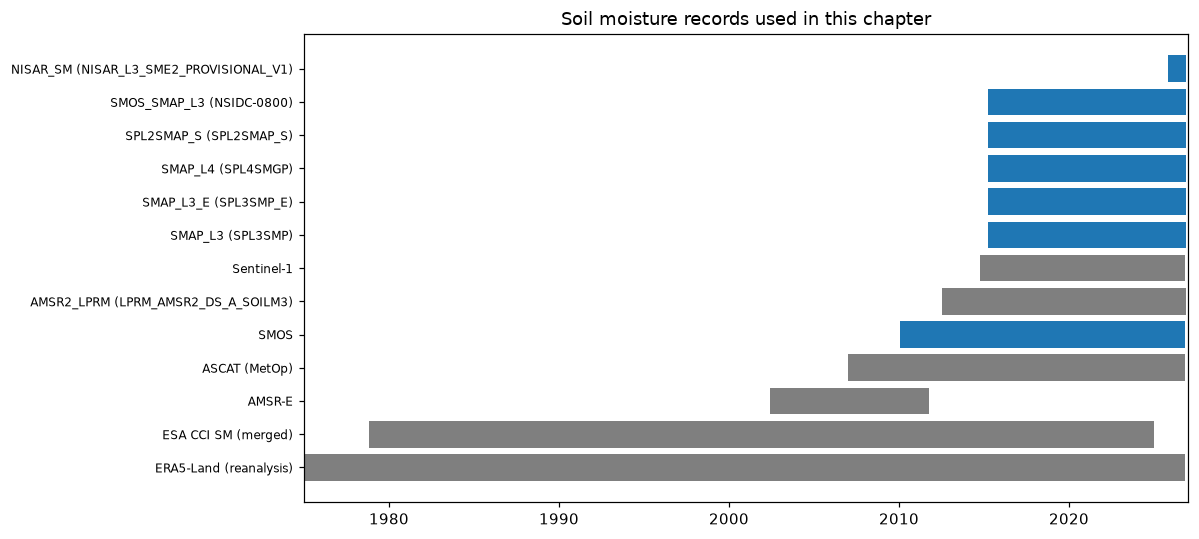

In [4]:
periods = {"ESA CCI SM (merged)": ("1978-11-01", "2024-12-31"), "ERA5-Land (reanalysis)": ("1950-01-01", "2026-11-01"),
           "AMSR-E": ("2002-06-01", "2011-10-04"), "ASCAT (MetOp)": ("2007-01-01", "2026-11-01"),
           "SMOS": ("2010-01-12", "2026-11-01"), "Sentinel-1": ("2014-10-03", "2026-11-01")}  # provider periods
for name, row in nasa.iterrows():  # NASA periods from CMR
    end = "2026-11-25" if row.time_end == "present" else row.time_end  # open-ended collections
    periods[f"{name} ({row.short_name})"] = (row.time_start, end)  # add
tl = pd.DataFrame(periods, index=["start", "end"]).T.apply(pd.to_datetime).sort_values("start")  # table
fig, ax = plt.subplots(figsize=(11, 5))  # Gantt chart
for i, (name, r) in enumerate(tl.iterrows()):  # one bar per record
    ax.barh(i, (r.end - r.start).days, left=r.start, color="tab:blue" if "SMAP" in name or "NISAR" in name or "SMOS" in name else "tab:gray")  # bar
ax.set_yticks(range(len(tl))); ax.set_yticklabels(tl.index, fontsize=8); ax.set_xlim(pd.Timestamp("1975"), pd.Timestamp("2027"))  # labels
ax.set_title("Soil moisture records used in this chapter"); plt.tight_layout(); plt.show()  # draw

## Latency: how fresh is each product

Latency is the delay between observation and availability. The newest granule of each NASA
collection shows it directly.

In [5]:
rows = []  # newest granule per collection
for name, row in nasa.iterrows():  # each NASA product
    r = requests.get(f"{sm.CMR}/granules.json", params={"short_name": row.short_name, "version": row.version,
                                                       "sort_key": "-start_date", "page_size": 1}, timeout=60).json()  # newest first
    e = r["feed"]["entry"]  # granule list
    if e:  # found one
        newest = pd.Timestamp(e[0]["time_start"]).tz_localize(None)  # acquisition time
        rows.append({"product": name, "newest granule": newest.strftime("%Y-%m-%d"), "age (days)": (pd.Timestamp("2026-11-25") - newest).days})  # age
display(pd.DataFrame(rows).set_index("product"))  # latency table (queried on the day the notebook ran)

,newest granule,age (days)
product,,
SMAP_L3,2026-11-24,1
SMAP_L3_E,2026-11-24,1
SMAP_L4,2026-11-23,1
SPL2SMAP_S,2026-06-30,147
SMOS_SMAP_L3,2026-10-09,47
AMSR2_LPRM,2026-11-24,0
NISAR_SM,2026-10-21,34


On the day this notebook ran, the newest SMAP L3, L3 Enhanced and L4 granules were one day old
and AMSR2 LPRM had that day's data. The SMOS-SMAP product lagged by about seven weeks, the NISAR soil
moisture by about a month, and the SMAP/Sentinel-1 active-passive product by about five months, since
it waits for Sentinel-1 acquisitions that coincide with SMAP. Merged climate records such as ESA CCI
are released once a year. For monitoring, only the radiometer products are fresh enough.

## Four products on one day

The best-covered day of June 2024 over Iowa and its neighbours at 36 km (SMAP L3), 9 km (SMAP L3
Enhanced), 0.25 degree (ESA CCI COMBINED) and 0.5 degree (ERA5-Land points).

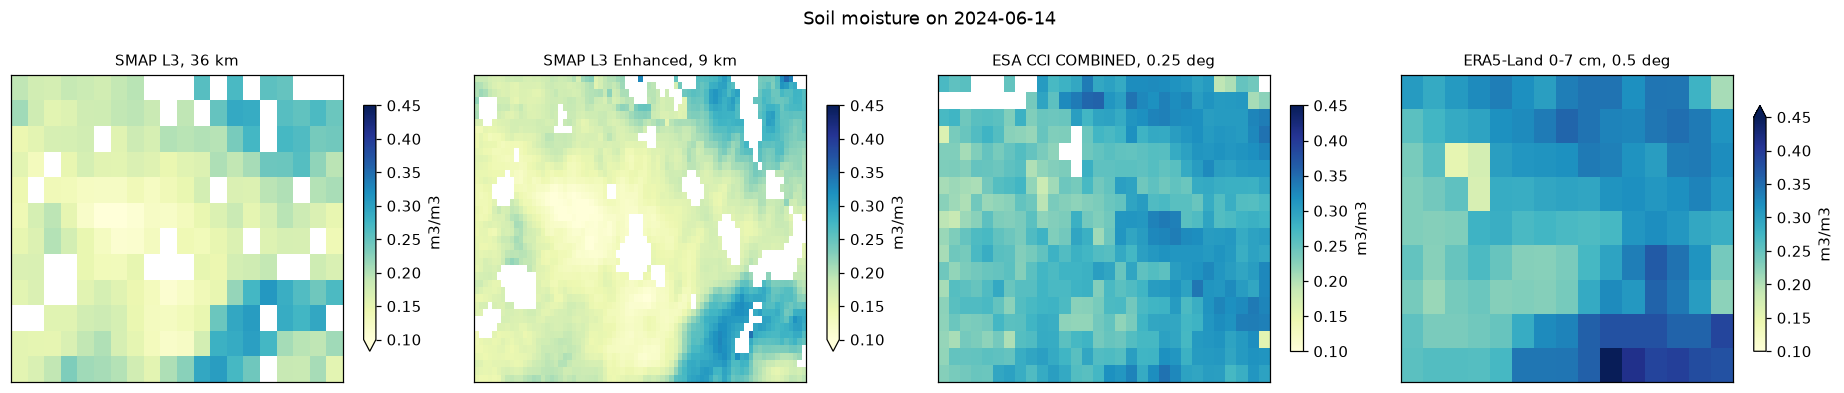

,mean,spatial std,cells
SMAP L3,0.185,0.049,206.0
SMAP L3E,0.180,0.050,2761.0
ESA CCI,0.273,0.036,522.0
ERA5-Land,0.298,0.052,135.0


In [6]:
l3e_june = sm.daily_cube(sm.mask_quality(sd.ease2_clip(sd.smap_l3e(), sd.IOWA_REGION).sel(time=slice("2024-06-01", "2024-06-30")))).sm  # SMAP 9 km, June 2024
day = pd.Timestamp(l3e_june.time.values[int(l3e_june.notnull().sum(("y", "x")).argmax())]).strftime("%Y-%m-%d")  # best covered day
l3e = l3e_june.sel(time=day)  # SMAP 9 km on that day
l3 = sm.daily_cube(sm.mask_quality(sd.smap_l3())).sm.sel(time=day)  # SMAP 36 km, AM first
cci = sd.cci("COMBINED").sm.sel(time=day)  # ESA CCI 0.25 degree
era = sd.era5_land().swvl1.sel(time=day)  # ERA5-Land 0.5 degree
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))  # four maps
for a, (name, da) in zip(ax, [("SMAP L3, 36 km", l3), ("SMAP L3 Enhanced, 9 km", l3e), ("ESA CCI COMBINED, 0.25 deg", cci), ("ERA5-Land 0-7 cm, 0.5 deg", era)]):  # each product
    da.plot(ax=a, vmin=0.1, vmax=0.45, cmap="YlGnBu", add_colorbar=True, cbar_kwargs={"shrink": 0.8, "label": "m3/m3"})  # map
    a.set_title(name, fontsize=10); a.set_xlabel(""); a.set_ylabel(""); a.set_xticks([]); a.set_yticks([])  # clean axes
plt.suptitle(f"Soil moisture on {day}"); plt.tight_layout(); plt.show()  # draw
summary = pd.DataFrame({k: [float(v.mean()), float(v.std()), int(v.notnull().sum())] for k, v in
                        {"SMAP L3": l3, "SMAP L3E": l3e, "ESA CCI": cci, "ERA5-Land": era}.items()},
                       index=["mean", "spatial std", "cells"]).T  # statistics per product
display(summary.round(3))  # table

On 14 June 2024, the best-covered day of the month, the two SMAP products agree closely (regional
means of 0.185 and 0.180 m3 m-3) and show the same dry west and wet south-east; the 9 km grid adds
detail but no new information beyond the radiometer footprint, since it is interpolated from the
same observations. ESA CCI COMBINED (0.27) and ERA5-Land (0.30) show a similar east-west gradient but
are about 0.1 m3 m-3 wetter: the CCI record is rescaled to the climatology of the GLDAS land model
before merging, and model soil moisture is defined by the model's own soil parameters. Comparing
products therefore needs anomalies or rescaling (notebooks 10 and 22), not raw values.

## Summary and exercises

- Products fall into L-band radiometers, C/X-band radiometers, scatterometers, SAR, merged
  records and models; each has its own trade-off between resolution, revisit, record length
  and sensing depth.
- CMR gives versions, periods and the newest granule of NASA collections without a login.
- SMAP and SMOS use the EASE-Grid 2.0, the climate and reanalysis records regular latitude and
  longitude grids.
- On the same day the products agree on the pattern but not on the level: the CCI and ERA5-Land
  values were about 0.1 m3 m-3 wetter than SMAP.

**Exercises**

1. Add the AMSR2 LPRM and NISAR collections to the latency table. Which is the most recent NISAR
   granule over Iowa? (Use `sm.search_product("NISAR_SM", sd.IOWA["bbox"], (start, end))`.)
2. Repeat the four-product comparison for a dry day in August 2023. Do the products still agree
   on the pattern?
3. Use `sm.ease2_grid("EASE2_M36km", aoi=sd.IOWA["bbox"])` to count how many 9 km cells fall in each
   36 km cell.